### 04 — PCE Analysis

This notebook compiles the same filtering, ion-validation, device-configuration and configuration aggregation workflow used in `02_Hussain model recreation.ipynb` but predicting power conversion efficiency (PCE) instead of Band Gap.

**Target:** `mean_PCE` (aggregated configurations), then `JV_default_PCE` (individual records).

**Inputs:** composition (A/B/X ion coefficients), device architecture and stack sequences.

**Not required:** `Perovskite_band_gap`, `JV_default_Jsc`, `JV_default_Voc`, `JV_default_FF` or `Measured_Cell_Area`. These are deliberately excluded from this notebook's modelling inputs and missing-value filters.

The same common-layer settings (`MIN_FREQUENCY=100`, `TOP_N=5`) and **mean/median aggregation** are retained. Device area has been added to the configuration key so experiments at different areas are not merged. Outputs go to `Data/PCE_Analysis` so the original band-gap files remain untouched.

In [20]:

import pandas as pd
import numpy as np
from pathlib import Path

# Import the original Perovskite Database
df = pd.read_csv(
    "Data/Perovskite_database_full.csv",
    encoding="cp1252",
    low_memory=False
)

print(df.shape)


(42851, 410)


In [21]:

# Select the relevant columns for PCE analysis
df_hussain = df[[
    # Reference
    'Ref_ID',
    'Ref_DOI_number',

    # Composition
    'Perovskite_composition_a_ions',
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions',
    'Perovskite_composition_c_ions_coefficients',
    'Perovskite_composition_short_form',

    # Device Structure
    'Cell_architecture',
    'Cell_area_measured',
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence',

    # Performance
    'JV_default_PCE',
    'JV_default_Jsc',
    'JV_default_Voc',
    'JV_default_FF'
]].copy()

print(df_hussain.shape)


(42851, 19)


This is the main change from band-gap analysis: require the **PCE target** and measured cell area rather than band gap, Jsc, Voc and fill factor. Ion identities/coefficients and device layers are needed by the model, so entries lacking these are also excluded. (Layer restriction in Filter 3 would otherwise remove missing layer sequences.)

In [ ]:

# Filter 1: Remove records missing essential data

required_fields = [
    # Composition
    'Perovskite_composition_short_form',
    'Perovskite_composition_a_ions',
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions',
    'Perovskite_composition_c_ions_coefficients',

    # Cell area
    'Cell_area_measured',

    # Performance
    'JV_default_PCE',
    'JV_default_Jsc',
    'JV_default_Voc',
    'JV_default_FF'
]

df_filtered_1 = df_hussain.dropna(
    subset=required_fields
).copy()

print("Before Filter 1:", len(df_hussain))
print("After Filter 1:", len(df_filtered_1))
print("Removed:", len(df_hussain) - len(df_filtered_1))




# FILTER 2: Permitted perovskite ions

ALLOWED_A = ['MA', 'FA', 'Cs']
ALLOWED_B = ['Pb', 'Sn']
ALLOWED_X = ['I', 'Br', 'Cl']

def valid_ions(cell, allowed):
    if pd.isna(cell):
        return False

    ions = [ion.strip() for ion in str(cell).split(';')]
    return all(ion in allowed for ion in ions)

valid_a = df_filtered_1['Perovskite_composition_a_ions'].apply(
    lambda value: valid_ions(value, ALLOWED_A)
)
valid_b = df_filtered_1['Perovskite_composition_b_ions'].apply(
    lambda value: valid_ions(value, ALLOWED_B)
)
valid_x = df_filtered_1['Perovskite_composition_c_ions'].apply(
    lambda value: valid_ions(value, ALLOWED_X)
)

df_filtered_2 = df_filtered_1[
    valid_a & valid_b & valid_x
].copy()

print("Filter 2:", len(df_filtered_2), "records remaining")



# FILTER 3: Common device configurations

MIN_FREQUENCY = 100
TOP_N = 5

layer_columns = [
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence'
]

def accepted_layers(data, column, min_frequency, top_n):
    counts = data[column].value_counts()
    counts = counts[counts >= min_frequency]
    return counts.head(top_n).index

df_filtered_3 = df_filtered_2.copy()

for column in layer_columns:
    allowed = accepted_layers(
        df_filtered_2, column, MIN_FREQUENCY, TOP_N
    )

    df_filtered_3 = df_filtered_3[
        df_filtered_3[column].isin(allowed)
    ].copy()

print("Filter 3:", len(df_filtered_3), "records remaining")




# FILTER 4: Identify exact duplicates

duplicate_columns = [
    'Ref_DOI_number',
    'Perovskite_composition_short_form',
    'Cell_architecture',
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence',
    'JV_default_PCE',
    'JV_default_Jsc',
    'JV_default_Voc',
    'JV_default_FF'
]

duplicates = df_filtered_3.duplicated(
    subset=duplicate_columns,
    keep='first'
)

print("Filter 4: Potential duplicates:", duplicates.sum())

# Duplicates are only identified, not removed.




# FILTER 5: Physical validity checks

VALID_RANGES = {
    'JV_default_PCE': (0, 100),
    'JV_default_Jsc': (0, None),
    'JV_default_Voc': (0, None)
}

df_filtered_5 = df_filtered_3.copy()

for column, (minimum, maximum) in VALID_RANGES.items():

    values = pd.to_numeric(
        df_filtered_5[column], errors='coerce'
    )

    valid = np.isfinite(values)

    if minimum is not None:
        valid = valid & (values >= minimum)

    if maximum is not None:
        valid = valid & (values <= maximum)

    df_filtered_5 = df_filtered_5[valid].copy()

print("Filter 5:", len(df_filtered_5), "records remaining")




# ADDITIONAL ORIGINAL CHECK: Valid ion coefficients

coefficient_columns = [
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions_coefficients'
]

def valid_coefficients(value):
    if pd.isna(value):
        return False

    coefficients = str(value).split(';')

    for coefficient in coefficients:
        try:
            number = float(coefficient.strip())
            if not np.isfinite(number) or number <= 0:
                return False
        except ValueError:
            return False

    return True

valid_rows = pd.Series(True, index=df_filtered_5.index)

for column in coefficient_columns:
    valid_rows &= df_filtered_5[column].apply(
        valid_coefficients
    )

df_filtered_5 = df_filtered_5.loc[valid_rows].copy()

print("After coefficient checks:", len(df_filtered_5))




# FINAL FILTERING SUMMARY

print("\n--- FILTERING SUMMARY ---")
print("Original:", len(df_hussain))
print("Filter 1:", len(df_filtered_1))
print("Filter 2:", len(df_filtered_2))
print("Filter 3:", len(df_filtered_3))
print("Filter 5 + coefficients:", len(df_filtered_5))
print("Total removed:", len(df_hussain) - len(df_filtered_5))
print("Percentage retained:",
      round(100 * len(df_filtered_5) / len(df_hussain), 2), "%")



Before Filter 1: 42851
After Filter 1: 39461
Removed: 3390
Filter 2: 37295 records remaining
Filter 3: 22358 records remaining
Filter 4: Potential duplicates: 572
Filter 5: 22358 records remaining
After coefficient checks: 22318

--- FILTERING SUMMARY ---
Original: 42851
Filter 1: 39461
Filter 2: 37295
Filter 3: 22358
Filter 5 + coefficients: 22318
Total removed: 20533
Percentage retained: 52.08 %


The above block imported the same filters/checks from Hussain model learnt while trying to recreate the Hussain model. The only change was removing band gap entirely, as it was not measured each time and isn't needed for calculating PCE.

The next block is a PCE-specific filters, as there were no filters for it beforehand as it wasn't used. This filter applies physical logic checks to cell area (positive and finite), fill factor (between 0-1). No checks are applied to PCE before we see results.

In [23]:

# FILTER 6: PCE-specific physical validity

df_filtered_6 = df_filtered_5.copy()

# Convert relevant columns to numeric values
for column in ['Cell_area_measured', 'JV_default_FF']:
    df_filtered_6[column] = pd.to_numeric(
        df_filtered_6[column], errors='coerce'
    )

# Cell area must be positive
valid_area = (
    np.isfinite(df_filtered_6['Cell_area_measured']) &
    (df_filtered_6['Cell_area_measured'] > 0)
)

# Fill factor must be between 0 and 1
valid_ff = (
    np.isfinite(df_filtered_6['JV_default_FF']) &
    df_filtered_6['JV_default_FF'].between(0, 1)
)

df_filtered_6 = df_filtered_6[
    valid_area & valid_ff
].copy()

# Summary
print("Before Filter 6:", len(df_filtered_5))
print("After Filter 6:", len(df_filtered_6))
print("Removed:", len(df_filtered_5) - len(df_filtered_6))
print("Total retained:", round(
    100 * len(df_filtered_6) / len(df_hussain), 2
), "%")


Before Filter 6: 22318
After Filter 6: 22307
Removed: 11
Total retained: 52.06 %


In [24]:

# AGGREGATION BY CONFIGURATION

MIN_RECORDS = 1

OUTPUT_FOLDER = Path("Data/PCE_Analysis")
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

# Define identical device configurations
configuration_columns = [
    # Perovskite composition
    'Perovskite_composition_a_ions',
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions',
    'Perovskite_composition_c_ions_coefficients',

    # Device architecture
    'Cell_architecture',
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence'
]

# Convert measurements to numeric values
measurement_columns = [
    'JV_default_PCE',
    'JV_default_Jsc',
    'JV_default_Voc',
    'JV_default_FF'
]

df_numeric = df_filtered_6.copy()

for column in measurement_columns:
    df_numeric[column] = pd.to_numeric(
        df_numeric[column], errors='coerce'
    )

# Aggregate experimental observations
df_configurations = (
    df_numeric
    .groupby(configuration_columns, dropna=False)
    .agg(
        # Number of observations
        n_records=('JV_default_PCE', 'size'),

        # Power conversion efficiency
        mean_PCE=('JV_default_PCE', 'mean'),
        median_PCE=('JV_default_PCE', 'median'),
        std_PCE=('JV_default_PCE', 'std'),

        # Photovoltaic parameters
        mean_Jsc=('JV_default_Jsc', 'mean'),
        std_Jsc=('JV_default_Jsc', 'std'),

        mean_Voc=('JV_default_Voc', 'mean'),
        std_Voc=('JV_default_Voc', 'std'),

        mean_FF=('JV_default_FF', 'mean'),
        std_FF=('JV_default_FF', 'std')
    )
    .reset_index()
)

# Minimum observation requirement
df_configurations_filtered = df_configurations[
    df_configurations['n_records'] >= MIN_RECORDS
].copy()

# Save aggregated dataset
df_configurations_filtered.to_csv(
    OUTPUT_FOLDER / "Aggregated_Configurations_PCE.csv",
    index=False,
    encoding='utf-8'
)

# Save cleaned but unaggregated dataset
df_filtered_6.to_csv(
    OUTPUT_FOLDER / "Filtered_Experimental_Records_PCE.csv",
    index=False,
    encoding='utf-8'
)

# Summary
print("Original records:", len(df_hussain))
print("Filtered records:", len(df_filtered_6))
print("Unique configurations:", len(df_configurations))
print("Final configurations:", len(df_configurations_filtered))
print("Records represented:", df_configurations_filtered['n_records'].sum())
print("Single-observation configurations:",
      (df_configurations_filtered['n_records'] == 1).sum())

print("\nDatasets saved to:", OUTPUT_FOLDER)


Original records: 42851
Filtered records: 22307
Unique configurations: 2125
Final configurations: 2125
Records represented: 22307
Single-observation configurations: 963

Datasets saved to: Data/PCE_Analysis


This aggregates to a similiar amount of inputs as the band gap, which is promising considering almost identical filters and aggregation methods were used as the band gap predictions.

Aggregated configurations: 2125
Usable configurations: 2100
Excluded configurations: 25


,MA,FA,Cs,Pb,Sn,I,Br,Cl,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,HTL_stack_sequence,Backcontact_stack_sequence
0,0.0,0.0,0.003,0.997,0.0,0.00,3.00,0.0,nip,SLG | FTO,TiO2-c | TiO2-mp,none,Carbon
1,0.0,0.0,0.005,0.995,0.0,0.00,3.00,0.0,nip,SLG | FTO,TiO2-c | TiO2-mp,none,Carbon
2,0.0,0.0,0.005,0.995,0.0,1.01,1.99,0.0,nip,SLG | FTO,TiO2-c | TiO2-mp,none,Carbon
3,0.0,0.0,0.010,0.990,0.0,0.00,3.00,0.0,nip,SLG | FTO,TiO2-c | TiO2-mp,none,Carbon
4,0.0,0.0,0.010,0.990,0.0,1.02,1.98,0.0,nip,SLG | FTO,TiO2-c | TiO2-mp,none,Carbon


Training samples: 1680
Testing samples: 420
Optimal alpha: 13.3352
Cross-validation RMSE: 3.8532

--- RIDGE REGRESSION: PCE ---
Optimal alpha: 13.3352

Training Performance:
RMSE: 3.7467 percentage points
MAE: 2.9419 percentage points
R²: 0.5085

Testing Performance:
RMSE: 3.6791 percentage points
MAE: 2.9281 percentage points
R²: 0.4843


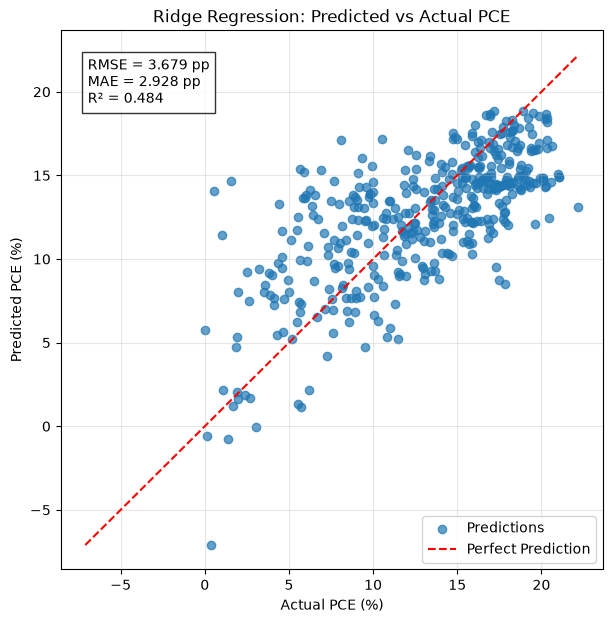


Largest coefficients:


,Feature,Ridge_weight
40,device__HTL_stack_sequence_none,-3.367151
38,device__HTL_stack_sequence_PTAA,2.259645
39,device__HTL_stack_sequence_Spiro-MeOTAD,2.147529
22,device__ETL_stack_sequence_SnO2-np,1.584622
27,device__ETL_stack_sequence_ZnO-c,-1.378390
30,device__HTL_stack_sequence_CuSCN,-1.267554
37,device__HTL_stack_sequence_PEDOT:PSS,-1.149073
36,device__HTL_stack_sequence_P3HT,-1.067296
19,device__ETL_stack_sequence_PCBM-60 | C60 | BCP,1.052277
31,device__HTL_stack_sequence_NiMgLiO,1.017846



Total configurations: 2100
Unique chemical compositions: 792
Repeated compositions: 1308


In [25]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


data_pce = pd.read_csv(
    "Data/PCE_Analysis/Aggregated_Configurations_PCE.csv"
)

ion_columns = [
    'Perovskite_composition_a_ions',
    'Perovskite_composition_b_ions',
    'Perovskite_composition_c_ions'
]

coefficient_columns = [
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions_coefficients'
]

allowed_ions = [
    'MA', 'FA', 'Cs',
    'Pb', 'Sn',
    'I', 'Br', 'Cl'
]

device_columns = [
    'Cell_architecture',
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence'
]

print("Aggregated configurations:", len(data_pce))



def encode_composition(row): #Ion compositions are encoded.

    composition = {ion: 0.0 for ion in allowed_ions}
    total = 0.0

    for ion_column, coefficient_column in zip(
        ion_columns, coefficient_columns
    ):

        ions = [
            ion.strip()
            for ion in str(row[ion_column]).split(';')
        ]

        try:
            coefficients = [
                float(value.strip())
                for value in str(row[coefficient_column]).split(';')
            ]
        except (ValueError, TypeError):
            return None

        if len(ions) != len(coefficients):
            return None

        for ion, coefficient in zip(ions, coefficients):

            if ion not in composition:
                return None

            if not np.isfinite(coefficient) or coefficient <= 0:
                return None

            composition[ion] += coefficient
            total += coefficient

    # Same composition-total validation as previous model
    if not 2 <= total <= 6:
        return None

    return composition


encoded_rows = []
valid_indices = []

for index, row in data_pce.iterrows():

    encoded = encode_composition(row)

    if encoded is not None and pd.notna(row['mean_PCE']):
        encoded_rows.append(encoded)
        valid_indices.append(index)

X = pd.DataFrame(
    encoded_rows,
    index=valid_indices,
    columns=allowed_ions
)

# Include device configurations as additional inputs
X = X.join(
    data_pce.loc[valid_indices, device_columns].fillna('Unknown')
)

# Prediction target
y = pd.to_numeric(
    data_pce.loc[valid_indices, 'mean_PCE'],
    errors='coerce'
)

valid_target = np.isfinite(y)
X = X.loc[valid_target]
y = y.loc[valid_target]

print("Usable configurations:", len(X))
print("Excluded configurations:", len(data_pce) - len(X))

display(X.head())


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))



# StandardScaler for numerical ion coefficients
# OneHotEncoder for categorical device configurations

preprocessor = ColumnTransformer(
    transformers=[
        ('ions', StandardScaler(), allowed_ions),
        ('device', OneHotEncoder(handle_unknown='ignore'), device_columns)
    ],
    sparse_threshold=0
)


#Test 5-fold cross-validation to find the optimal alpha for Ridge regression.
alpha_values = np.logspace(0, 3, 25)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

alpha_scores = []

for alpha in alpha_values:

    pipeline = make_pipeline(
        preprocessor,
        Ridge(alpha=alpha)
    )

    rmse_scores = -cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='neg_root_mean_squared_error'
    )

    alpha_scores.append(rmse_scores.mean())

best_alpha = alpha_values[np.argmin(alpha_scores)]

print("Optimal alpha:", round(best_alpha, 4))
print("Cross-validation RMSE:", round(min(alpha_scores), 4))



ridge_model = make_pipeline(
    preprocessor,
    Ridge(alpha=best_alpha)
)

ridge_model.fit(X_train, y_train)

# Training predictions
y_train_pred = ridge_model.predict(X_train)

# Testing predictions
y_test_pred = ridge_model.predict(X_test)


#Model performance evaluation:
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_mae = mean_absolute_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_mae = mean_absolute_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("\n--- RIDGE REGRESSION: PCE ---")
print("Optimal alpha:", round(best_alpha, 4))

print("\nTraining Performance:")
print("RMSE:", round(train_rmse, 4), "percentage points")
print("MAE:", round(train_mae, 4), "percentage points")
print("R²:", round(train_r2, 4))

print("\nTesting Performance:")
print("RMSE:", round(test_rmse, 4), "percentage points")
print("MAE:", round(test_mae, 4), "percentage points")
print("R²:", round(test_r2, 4))




plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.7,
    label='Predictions'
)

min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual PCE (%)")
plt.ylabel("Predicted PCE (%)")
plt.title("Ridge Regression: Predicted vs Actual PCE")

plt.text(
    0.05, 0.95,
    f"RMSE = {test_rmse:.3f} pp\n"
    f"MAE = {test_mae:.3f} pp\n"
    f"R² = {test_r2:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()



feature_names = (
    ridge_model.named_steps['columntransformer']
    .get_feature_names_out()
)

coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Ridge_weight': ridge_model.named_steps['ridge'].coef_
})

coefficients = coefficients.reindex(
    coefficients['Ridge_weight'].abs()
    .sort_values(ascending=False).index
)

print("\nLargest coefficients:")
display(coefficients.head(20))


unique_compositions = X[allowed_ions].drop_duplicates()

print("\nTotal configurations:", len(X))
print("Unique chemical compositions:", len(unique_compositions))
print("Repeated compositions:", len(X) - len(unique_compositions))


This ML model was exceptionally poor at predicting PCE, opting to chose "safe", middle values rather than accurate predictions, resulting in a blob of results in the center. Looking through the ridge regression values, "device__HTL_stack_sequence_none" was immediately suspicious as we did not yet know that a solar cell can have no HTL. We researched, and checked that this didn't mean that no information was available - and concluded it meant the Perovskite was connected directly to the backplate. So we decided to investigate if this causing poor predictions from being too different to compare.

Original training configurations: 1680
Filtered training configurations: 1562
Original testing configurations: 420
Filtered testing configurations: 383

Original alpha: 13.33521432163324
Filtered alpha: 23.71373705661655

--- MODEL COMPARISON ---


,RMSE,MAE,R²
Original model (same test set),3.6877,2.9213,0.4403
HTL/ETL-required model,3.6818,2.9130,0.4421


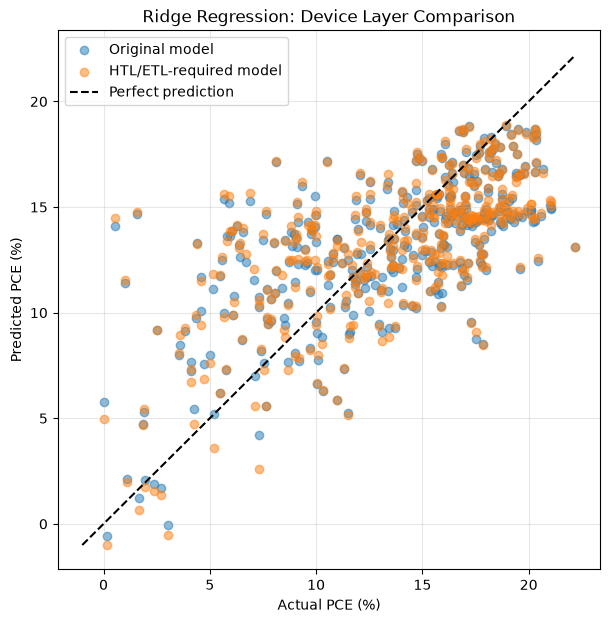

In [26]:

from sklearn.base import clone

# Check whether each configuration contains
# an HTL, ETL and valid A/B/X perovskite composition

def has_required_layers(data):

    def layer_present(column):
        values = data[column].fillna('').astype(str).str.strip().str.lower()
        return ~values.isin(['none', 'unknown', '', 'nan'])

    has_htl = layer_present('HTL_stack_sequence')
    has_etl = layer_present('ETL_stack_sequence')

    has_perovskite = (
        (data[['MA', 'FA', 'Cs']].sum(axis=1) > 0) &
        (data[['Pb', 'Sn']].sum(axis=1) > 0) &
        (data[['I', 'Br', 'Cl']].sum(axis=1) > 0)
    )

    return has_htl & has_etl & has_perovskite


# Apply filtering to the EXISTING train/test split
train_mask = has_required_layers(X_train)
test_mask = has_required_layers(X_test)

X_train_present = X_train.loc[train_mask]
y_train_present = y_train.loc[train_mask]

X_test_present = X_test.loc[test_mask]
y_test_present = y_test.loc[test_mask]

print("Original training configurations:", len(X_train))
print("Filtered training configurations:", len(X_train_present))
print("Original testing configurations:", len(X_test))
print("Filtered testing configurations:", len(X_test_present))



filtered_scores = []

for alpha in alpha_values:

    model = make_pipeline(
        clone(preprocessor),
        Ridge(alpha=alpha)
    )

    scores = -cross_val_score(
        model,
        X_train_present,
        y_train_present,
        cv=cv,
        scoring='neg_root_mean_squared_error'
    )

    filtered_scores.append(scores.mean())

best_alpha_present = alpha_values[np.argmin(filtered_scores)]


ridge_present = make_pipeline(
    clone(preprocessor),
    Ridge(alpha=best_alpha_present)
)

ridge_present.fit(X_train_present, y_train_present)

# Predictions on IDENTICAL test configurations
pred_original = ridge_model.predict(X_test_present)
pred_filtered = ridge_present.predict(X_test_present)



def calculate_metrics(actual, predicted):
    return {
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'MAE': mean_absolute_error(actual, predicted),
        'R²': r2_score(actual, predicted)
    }

comparison = pd.DataFrame({
    'Original model (same test set)': calculate_metrics(
        y_test_present, pred_original
    ),
    'HTL/ETL-required model': calculate_metrics(
        y_test_present, pred_filtered
    )
}).T

print("\nOriginal alpha:", best_alpha)
print("Filtered alpha:", best_alpha_present)

print("\n--- MODEL COMPARISON ---")
display(comparison.round(4))



plt.figure(figsize=(7, 7))

plt.scatter(
    y_test_present, pred_original,
    alpha=0.5, label='Original model'
)

plt.scatter(
    y_test_present, pred_filtered,
    alpha=0.5, label='HTL/ETL-required model'
)

limits = [
    min(y_test_present.min(), pred_original.min(), pred_filtered.min()),
    max(y_test_present.max(), pred_original.max(), pred_filtered.max())
]

plt.plot(limits, limits, 'k--', label='Perfect prediction')

plt.xlabel('Actual PCE (%)')
plt.ylabel('Predicted PCE (%)')
plt.title('Ridge Regression: Device Layer Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


This change resulted in even worse results, and was therefore written off as the potential cause of poor predictions. We decided to keep no-HTL configurations in the aggregated dataset.

The next potential impact was aggregation, this was a slight concern for band gap, but the results were accurate enough to ignore the potential impacts. PCE uses open circuit voltage and short-circuit current density in its calculation, which means many variables used for the final PCE calculation can vary. This is less of an issue with large datasets, so it might be worth using a non-aggregated dataset. We will test how these values are affected by aggregation, then test non-aggregated if that doesn't lead us in another direction.

Total configurations: 2125
Configurations with 5+ records: 524
Median PCE range: 7.69
Configurations with range > 5 pp: 360
Configurations with range > 10 pp: 204


,composition,n_records,min_PCE,max_PCE,mean_PCE,median_PCE,std_PCE,PCE_range,PCE_80_range,ETL_stack_sequence,HTL_stack_sequence,Backcontact_stack_sequence
599,CsFAMAPbI,6,0.51,17.76,9.34,10.31,7.68,17.25,16.59,TiO2-c,Spiro-MeOTAD,Au
1802,MAPbI,7,0.53,19.00,9.95,12.30,7.56,18.47,16.88,ZnO-c,Spiro-MeOTAD,MoO3 | Ag
1469,FAMAPbBrI,5,0.11,17.51,7.23,4.39,7.34,17.40,14.48,TiO2-c | TiO2-mp,Spiro-MeOTAD,Au
1193,FAMAPbBrI,6,2.63,19.00,11.12,11.68,7.12,16.37,15.12,TiO2-c | TiO2-mp,Spiro-MeOTAD,Au
1468,FAMAPbI,8,0.20,20.59,16.93,19.18,6.88,20.39,8.88,SnO2-np,Spiro-MeOTAD,Au
942,FAPbI,10,0.70,18.20,9.13,6.92,6.70,17.50,14.94,PCBM-60,PEDOT:PSS,Ag
462,CsFAMAPbBrI,5,5.30,20.00,16.42,19.40,6.28,14.70,9.62,TiO2-c | TiO2-mp,Spiro-MeOTAD,Au
946,FAPbI,5,0.00,16.01,9.97,12.56,6.14,16.01,11.14,PCBM-60 | BCP,PEDOT:PSS,Ag
1499,MAPbBr,5,2.45,17.10,12.78,14.49,5.94,14.65,9.87,PCBM-60,NiO-c,Ag
784,CsFAMAPbBrI,10,1.26,17.67,11.12,12.30,5.88,16.41,15.08,SnO2-c,Spiro-MeOTAD,Ag


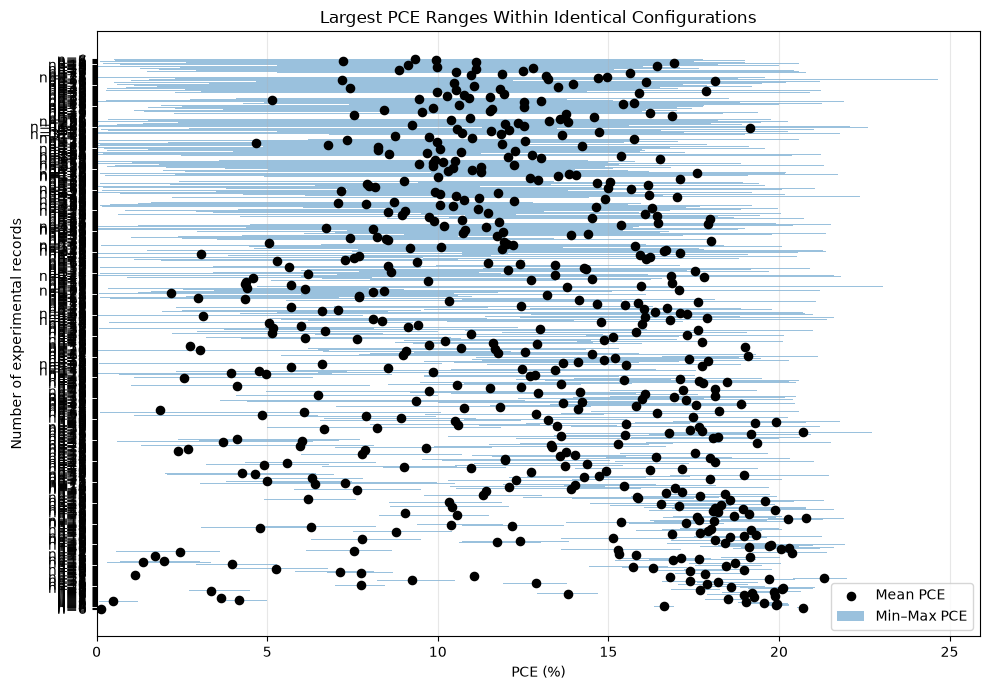

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', None)

df_records = pd.read_csv(
    "Data/PCE_Analysis/Filtered_Experimental_Records_PCE.csv"
)

# Same grouping columns as original aggregation
configuration_columns = [
    'Perovskite_composition_a_ions',
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions',
    'Perovskite_composition_c_ions_coefficients',
    'Cell_architecture',
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence'
]

# Calculate variation within each configuration
pce_spread = (
    df_records
    .groupby(configuration_columns, dropna=False)
    .agg(
        composition=('Perovskite_composition_short_form', 'first'),
        n_records=('JV_default_PCE', 'size'),
        min_PCE=('JV_default_PCE', 'min'),
        max_PCE=('JV_default_PCE', 'max'),
        mean_PCE=('JV_default_PCE', 'mean'),
        median_PCE=('JV_default_PCE', 'median'),
        std_PCE=('JV_default_PCE', 'std'),
        PCE_10th=('JV_default_PCE', lambda x: x.quantile(0.1)),
        PCE_90th=('JV_default_PCE', lambda x: x.quantile(0.9))
    )
    .reset_index()
)

pce_spread['PCE_range'] = (
    pce_spread['max_PCE'] - pce_spread['min_PCE']
)

pce_spread['PCE_80_range'] = (
    pce_spread['PCE_90th'] - pce_spread['PCE_10th']
)

# Require at least 5 observations for meaningful comparison
MIN_RECORDS = 5
TOP_N = 600

valid_groups = pce_spread[
    pce_spread['n_records'] >= MIN_RECORDS
]

largest_ranges = valid_groups.nlargest(
    TOP_N, 'std_PCE'
)

# Summary
print("Total configurations:", len(pce_spread))
print("Configurations with 5+ records:", len(valid_groups))
print("Median PCE range:", round(valid_groups['PCE_range'].median(), 2))
print("Configurations with range > 5 pp:",
      (valid_groups['PCE_range'] > 5).sum())
print("Configurations with range > 10 pp:",
      (valid_groups['PCE_range'] > 10).sum())

# Show the configurations with the largest variation
display(largest_ranges[[
    'composition',
    'n_records',
    'min_PCE',
    'max_PCE',
    'mean_PCE',
    'median_PCE',
    'std_PCE',
    'PCE_range',
    'PCE_80_range',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence'
]].round(2))

plot_data = largest_ranges.iloc[::-1]

plt.figure(figsize=(10, 7))

y_positions = np.arange(len(plot_data))

# Minimum to maximum PCE
plt.barh(
    y_positions,
    plot_data['PCE_range'],
    left=plot_data['min_PCE'],
    alpha=0.45,
    label='Min–Max PCE'
)

# Mean PCE
plt.scatter(
    plot_data['mean_PCE'],
    y_positions,
    color='black',
    s=35,
    label='Mean PCE',
    zorder=3
)

plt.yticks(
    y_positions,
    [f"n={n}" for n in plot_data['n_records']]
)

plt.xlabel("PCE (%)")
plt.ylabel("Number of experimental records")
plt.title("Largest PCE Ranges Within Identical Configurations")
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


In [28]:

# TEST: Remove high-variation configurations from training only

from sklearn.base import clone

STD_LIMIT = 3.0

# Find the PCE standard deviation for each training configuration
train_std = data_pce.loc[X_train.index, 'std_PCE']

# Keep configurations with SD <= 2
# Also retain single-observation configurations (SD = NaN)
keep_train = train_std.isna() | (train_std <= STD_LIMIT)

X_train_reduced = X_train.loc[keep_train]
y_train_reduced = y_train.loc[keep_train]

print("Original training size:", len(X_train))
print("Reduced training size:", len(X_train_reduced))
print("Configurations removed:", (~keep_train).sum())

# Reoptimise alpha
scores = []

for alpha in alpha_values:
    model = make_pipeline(
        clone(preprocessor),
        Ridge(alpha=alpha)
    )

    rmse = -cross_val_score(
        model,
        X_train_reduced,
        y_train_reduced,
        cv=cv,
        scoring='neg_root_mean_squared_error'
    )

    scores.append(rmse.mean())

best_alpha_reduced = alpha_values[np.argmin(scores)]

# Train reduced model
ridge_reduced = make_pipeline(
    clone(preprocessor),
    Ridge(alpha=best_alpha_reduced)
)

ridge_reduced.fit(X_train_reduced, y_train_reduced)

# Both models predict the SAME original test set
pred_original = ridge_model.predict(X_test)
pred_reduced = ridge_reduced.predict(X_test)

# Compare results
comparison = pd.DataFrame({
    'Original model': [
        np.sqrt(mean_squared_error(y_test, pred_original)),
        mean_absolute_error(y_test, pred_original),
        r2_score(y_test, pred_original)
    ],
    'SD-filtered model': [
        np.sqrt(mean_squared_error(y_test, pred_reduced)),
        mean_absolute_error(y_test, pred_reduced),
        r2_score(y_test, pred_reduced)
    ]
}, index=['RMSE', 'MAE', 'R²'])

display(comparison.round(4))

print("Original alpha:", best_alpha)
print("Reduced model alpha:", best_alpha_reduced)


Original training size: 1680
Reduced training size: 1442
Configurations removed: 238


,Original model,SD-filtered model
RMSE,3.6791,3.6794
MAE,2.9281,2.9053
R²,0.4843,0.4842


Original alpha: 13.33521432163324
Reduced model alpha: 17.78279410038923
